### Build A Basic Chatbot With Langgraph(GRAPH API)

In [87]:
# Annotated allows us to attach additional metadata to a type.
# In LangGraph, we use it to specify how a particular state variable
# should be updated using a reducer.
from typing import Annotated

# TypedDict lets us define the structure of our graph's state.
# It specifies what keys the state dictionary should contain
# and what type of values those keys should hold.
from typing_extensions import TypedDict

# StateGraph is used to create a graph-based workflow.
# START represents the entry point of the graph.
# END represents the point where the graph execution finishes.
from langgraph.graph import StateGraph, START, END

# add_messages is a built-in LangGraph reducer for message lists.
# It appends new messages to the existing conversation history,
# handles updates to messages with matching IDs, and supports deletion.
from langgraph.graph.message import add_messages # REDUCER


In [88]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [89]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [90]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="groq:openai/gpt-oss-120b")

In [91]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, client=<groq.resources.chat.completions.Completions object at 0x00000206DDF0BA80>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000206E0230050>, model_name='groq:openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [92]:
llm=init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000206DDF120F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000206DDF129F0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [93]:
## Node Functionality
def chatbot(state:State): # func recieves current graph state as argument
    return {"messages":[llm.invoke(state["messages"])]} 
#extract those msgs send to llm invoke then append back to messages

In [94]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

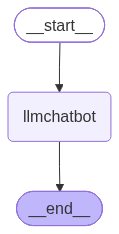

In [95]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [96]:
response=graph.invoke({"messages":"Hi"})

In [97]:
response["messages"][-1].content

'Hello! How can I assist you today?'

In [98]:
for event in graph.stream({"messages":"Hi How are you?"}): #Every iteration receives an event from the graph.
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thanks for asking. How can I assist you today?


### Chatbot With Tool

In [99]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [100]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [101]:
tools=[tool,multiply]

In [102]:
llm_with_tool=llm.bind_tools(tools)

In [103]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000206DDF120F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000206DDF129F0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for 

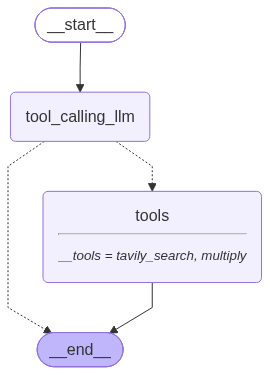

In [104]:
## State graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State): #new chatbot has an idea of all the tools, since its binded
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition 
)
builder.add_edge("tools",END) 
# else wali condn ka END mention nahi kiya kyuki voh tools_condn khud kardeta

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [105]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [106]:
response['messages'][-1].content

'{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today/edition/2026-11-21", "title": "AI News for November 21, 2026 — Daily Edition | AI Weekly", "content": "Useful releases, methods, and workflows worth trying.\\n\\nKyutai released AURA on November 20, an audio-driven video model that generates 576p talking-head video chunk by chunk at 20.7 fps on a single GPU in the 1.3B version, and 720p at 9.7 fps in the 5B version. Only the current audio chunk is needed to start generating, enabling low-latency voice avatars.\\n\\nOpenAI made its GPT-Live-1.1 voice model available in the API on November 20 and introduced a standby mode that bills idle time at $0.02 per minute versus $0.05 per minute for active inference, the company said on its developer community forum. Developers can set idle timeouts from 5 to 60 seconds on both GPT-Live-1 and 1.1.\\n\\nThat’s today’s shot. — Alexis · AI Weekly

In [107]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_7d9e4946-ff3d-4d6e-ab25-1d3f81333c99)
 Call ID: fc_7d9e4946-ff3d-4d6e-ab25-1d3f81333c99
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today/edition/2026-11-21", "title": "AI News for November 21, 2026 — Daily Edition | AI Weekly", "content": "Useful releases, methods, and workflows worth trying.\n\nKyutai released AURA on November 20, an audio-driven video model that generates 576p talking-head video chunk by chunk at 20.7 fps on a single GPU in the 1.3B ve

In [108]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [109]:
response=graph.invoke({"messages":"What is 5 multiplied by 3 and then multiplied by 10"})
for m in response['messages']:
    m.pretty_print()
    if m.type == "ai" and m.tool_calls:
        print("Tool calls:", m.tool_calls)

================================ Human Message =================================

What is 5 multiplied by 3 and then multiplied by 10
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_86af5768-e04e-44ae-805b-9b5b65d24974)
 Call ID: fc_86af5768-e04e-44ae-805b-9b5b65d24974
  Args:
    a: 5
    b: 3
Tool calls: [{'name': 'multiply', 'args': {'a': 5, 'b': 3}, 'id': 'fc_86af5768-e04e-44ae-805b-9b5b65d24974', 'type': 'tool_call'}]
================================= Tool Message =================================
Name: multiply

15


In [110]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()
    

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_7647ffdf-51a4-4172-8c75-fb38e25b66eb)
 Call ID: fc_7647ffdf-51a4-4172-8c75-fb38e25b66eb
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.linkedin.com/pulse/ai-news-day-november-20-2026-simran-sran-ljhcc", "title": "AI NEWS OF THE DAY - November 20, 2026", "content": "Google introduced Gemini 4 Hydrogen and Gemini 4 Neon, shortly after expanding availability of Gemini 4 Carbon. Gemini Tasks is also rolling out to help users handle multi-step work in the background.\n\nWhy it matt

### ReAct Agent Architecture

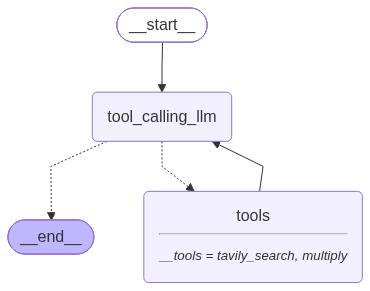

In [111]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm") #ReAct Agent Arch.

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [112]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_d14c1abe-e7f5-4ab7-81cd-4e2aa492691d)
 Call ID: fc_d14c1abe-e7f5-4ab7-81cd-4e2aa492691d
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=IsTGB5nyFdQ", "title": "Top 5 AI Developments That Just Changed the Game (November 2026)", "content": "moves from hype to real world medicine. Top scientists at seven pharma giants, Eli Lilly, Novo, Nordisk, Astroenica, Novartis, GSK, Bristol Meer, Squib, and Seni told Reuters that AI is already speeding up earl

## Adding Memory In Agentic Graph

In [113]:
response=graph.invoke({"messages":"Hello my name is KRish"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is KRish
================================== Ai Message ==================================

Hello Krish! Nice to meet you. How can I assist you today?


In [114]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t have any information about your name from our conversation so far. Could you let me know what you’d like to be called?


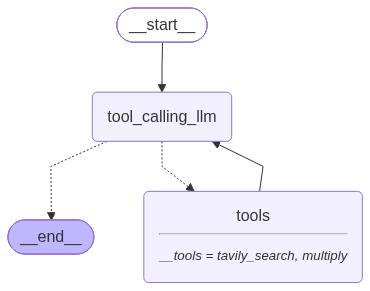

In [115]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [116]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Kaartik"},config=config)

response



{'messages': [HumanMessage(content='Hi my name is Kaartik', additional_kwargs={}, response_metadata={}, id='285883a3-79ad-4904-a730-468dfe1fab50'),
  AIMessage(content='Hi Kaartik! 👋 Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi my name is Kaartik". Likely a greeting. We can respond friendly, ask about how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 348, 'total_tokens': 409, 'completion_time': 0.126361759, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.016316628, 'prompt_tokens_details': None, 'queue_time': 0.287162993, 'total_time': 0.142678387}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_49bfac06f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20282-1c23-77cc-a58b-79c6813146cd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_toke

In [117]:
response['messages'][-1].content

'Hi Kaartik! 👋 Nice to meet you. How can I help you today?'

In [118]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Kaartik. 😊


In [119]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Yes, I remember—your name is Kaartik! Let me know if there’s anything you’d like to chat about or need help with.


### Streaming

In [120]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [121]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

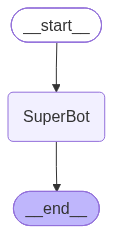

In [122]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [123]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Kaartik And I like MMA"},config)

{'messages': [HumanMessage(content='Hi,My name is Kaartik And I like MMA', additional_kwargs={}, response_metadata={}, id='998ef525-28e1-4916-9340-f5048bd3fb66'),
  AIMessage(content="Hey Kaartik! 👋 Great to meet you. \n\nMMA is such an exciting sport—there’s always something new happening in the octagon. Do you have any favorite fighters or promotions you follow? Are you more into the technical side of the game, the knockout highlights, or maybe you train yourself? I'd love to hear more about what draws you to MMA!", additional_kwargs={'reasoning_content': 'We need to respond. The user says hi, introduces themselves, likes MMA. We should greet them, maybe ask about their interest, ask about favorite fighters, etc. Should follow policy. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 132, 'prompt_tokens': 82, 'total_tokens': 214, 'completion_time': 0.276020715, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.

    Here -> Notice how the state grows with each execution step.
    - First, it contains the user's message.
    - Then, the AI's tool-call request is added.
    - Then, the tool result is added.
    - Finally, the AI's response is added.
This is because your add_messages reducer maintains the conversation history.
Think of values as repeatedly showing you the entire current state of your application.

- **updates** : This streams updates to the state of the graph after each node is called.

    Incase of updates -> 
    - The first event contains only the LLM node's update.
    - The second contains only the tool node's update.
    - The third contains only the LLM's final update.
    - It doesn't repeatedly give you the entire conversation history.
Think of updates as an activity log: what did each node contribute?

| Execution Step | Updates | Values |
|:---|:---|:---|
| LLM calls tool | Only AI's new message | Entire state including AI message |
| Tool executes | Only ToolMessage | Entire state including ToolMessage |
| LLM answers | Only final AI message | Entire state including final answer |

In [129]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Kaartik And I like MMA"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Kaartik! 👊 Nice to meet you.  \n\nSince you’re into MMA, here are a few quick things you might enjoy:\n\n| Category | Highlights (2024) |\n|----------|-------------------|\n| **Top Fighters** | **Islam Makhachev** (lightweight champ), **Alex Pereira** (middleweight champ), **Amanda Lemos** (women’s strawweight) |\n| **Upcoming Events** | UFC\u202f300 (Las\u202fVegas, Nov\u202f2024) – big fight card with multiple title bouts; ONE\u202fChampionship 2024‑25 season continues with exciting Asian matchups |\n| **Training Tips** | • **Fundamentals** – focus on solid footwork and basic grappling positions before flashy strikes.<br>• **Conditioning** – interval sprints (30\u202fsec on/30\u202fsec off) + kettlebell circuits mimic fight‑round intensity.<br>• **Drills** – shadow‑boxing + light‑sparring 3\u202f×\u202f/week builds timing without over‑training. |\n| **Must‑Watch Classic Fights** | *GSP vs. Khabib* (UFC\u202f229), *Anderson Silva vs. C

In [130]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Kaartik And I like MMA"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Kaartik And I like MMA', additional_kwargs={}, response_metadata={}, id='c1375d7a-2166-4f93-b1b7-23f9b8f6ef17'), AIMessage(content='Hey Kaartik! 👋 Nice to meet you. That’s awesome you’re into MMA—there’s always something exciting happening in the world of mixed martial arts. Do you have a favorite fighter or a particular promotion you follow (UFC, Bell\u202fBox, ONE, etc.)? Or maybe you train yourself? I’d love to hear more about what draws you to the sport!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Kaartik And I like MMA". Likely they are greeting, introducing themselves. We respond friendly, maybe ask about MMA interests. No disallowed content. Just a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 133, 'prompt_tokens': 82, 'total_tokens': 215, 'completion_time': 0.279823963, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.024156129, 'prompt_tokens_de

In [126]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Kaartik And I like MMA"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Kaartik! Nice to meet you. 😊\n\nMMA is such an exciting sport—there’s always something new happening in the octagon. Do you have a favorite fighter or a particular promotion you follow? Whether you’re into the technique, the strategy, or just love the high‑energy action, I’d love to hear what draws you to MMA!', additional_kwargs={'reasoning_content': 'We need to respond according to system and developer messages. System says: "You are ChatGPT, a large language model trained by OpenAI." Developer says: "You are ChatGPT, a large language model trained by OpenAI." So no special instruction beyond normal. User says: "Hi, My name is Kaartik And I like MMA". We should greet, maybe ask about MMA, keep conversation friendly. No disallowed content. So respond accordingly.'}, response_metadata={'token_usage': {'completion_tokens': 175, 'prompt_tokens': 82, 'total_tokens': 257, 'completion_time': 0.368719075, 'completion_tokens_details': {'reason

In [127]:
for chunk in graph_builder.stream({'messages':"I also like Agentic AI"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Kaartik And I like MMA', additional_kwargs={}, response_metadata={}, id='b920fe59-112a-4310-bcb1-69e6e2722f01'), AIMessage(content='Hey Kaartik! Nice to meet you. 😊\n\nMMA is such an exciting sport—there’s always something new happening in the octagon. Do you have a favorite fighter or a particular promotion you follow? Whether you’re into the technique, the strategy, or just love the high‑energy action, I’d love to hear what draws you to MMA!', additional_kwargs={'reasoning_content': 'We need to respond according to system and developer messages. System says: "You are ChatGPT, a large language model trained by OpenAI." Developer says: "You are ChatGPT, a large language model trained by OpenAI." So no special instruction beyond normal. User says: "Hi, My name is Kaartik And I like MMA". We should greet, maybe ask about MMA, keep conversation friendly. No disallowed content. So respond accordingly.'}, response_metadata={'token_usage': {'

In [ ]:
config = {"configurable": {"thread_id": "5"}}
#astream_events() -> much more details 
# You use async for because the graph is being executed asynchronously. 
#Async streaming doesn't mean the model is necessarily generating words faster. It means 
#your Python program can await results without blocking its event loop.
async for event in graph_builder.astream_events({"messages":["Hi My name is Kaartik and I like to fight"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Kaartik and I like to fight']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a20282-3d48-7274-bb49-7e2fdb241869', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Kaartik and I like to fight', additional_kwargs={}, response_metadata={}, id='b4b3efa1-290e-4248-b4a7-349ed6d36ad7')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a20282-3d4d-724d-8767-0405685cbfda', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:57fd7791-5eef-aac5-1658-ab46b2ae96e0'}, 'parent_ids': ['01a20282-3d48-7274-bb49-7e2fdb241869']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMe